# 04 - Multilayer Perceptron (MLP) Model

## Objective
Train and evaluate a two-hidden-layer Multilayer Perceptron (MLP) neural network regressor to predict students' AI Adoption Scores based on the six predictor variables (SOP 3).

### Predictor Variables (X):
1. `ai_familiarity_score`
2. `perceived_usefulness_score`
3. `perceived_ease_of_use_score`
4. `trust_score`
5. `accessibility_score`
6. `digital_literacy_score`

### Target Variable (y):
- `ai_adoption_score`

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths setup
cwd = Path.cwd()
project_candidates = [cwd, cwd.parent]
PROJECT_ROOT = next(
    (path for path in project_candidates if (path / "requirements.txt").is_file()),
    cwd,
)

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
GRAPHS_DIR = RESULTS_DIR / "graphs"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = DATA_DIR / "scored_data.csv"
print(f"Project root: {PROJECT_ROOT}")
print(f"Scored data path: {INPUT_PATH}")
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


Project root: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis
Scored data path: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\data\scored_data.csv


## Load Scored Dataset

In [6]:
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Scored dataset not found at {INPUT_PATH}. Please run 02_scoring.ipynb first."
    )

df = pd.read_csv(INPUT_PATH)
print(f"Loaded {len(df)} respondents.")

feature_cols = [
    "ai_familiarity_score",
    "perceived_usefulness_score",
    "perceived_ease_of_use_score",
    "trust_score",
    "accessibility_score",
    "digital_literacy_score",
]
target_col = "ai_adoption_score"

X = df[feature_cols].copy()
y = df[target_col].copy()

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
display(X.head())


Loaded 100 respondents.
Features shape: (100, 6)
Target shape: (100,)


,ai_familiarity_score,perceived_usefulness_score,perceived_ease_of_use_score,trust_score,accessibility_score,digital_literacy_score
0,3.666667,4.000000,3.333333,2.333333,3.333333,4.333333
1,5.000000,5.000000,5.000000,3.666667,3.666667,4.666667
2,4.000000,4.000000,4.000000,3.333333,4.333333,3.666667
3,4.333333,2.333333,4.000000,1.000000,3.666667,3.333333
4,4.333333,4.666667,4.000000,3.666667,3.333333,4.000000


## Model Specification & Cross-Validation

We evaluate the MLP model using Repeated 5-Fold Cross-Validation (10 repeats, random_state=42).
Feature scaling is fit on each training split via standard scaling to prevent data leakage.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

mlp = MLPRegressor(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    alpha=0.01,
    max_iter=1000,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20
)

rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

cv_results = cross_validate(
    mlp,
    X_scaled,
    y,
    cv=rkf,
    scoring={
        "neg_rmse": "neg_root_mean_squared_error",
        "neg_mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
    return_train_score=False,
)

rmse_scores = -cv_results["test_neg_rmse"]
mae_scores = -cv_results["test_neg_mae"]
r2_scores = cv_results["test_r2"]

metrics_df = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2"],
    "Mean": [rmse_scores.mean(), mae_scores.mean(), r2_scores.mean()],
    "Std": [rmse_scores.std(), mae_scores.std(), r2_scores.std()],
})
display(metrics_df)

mlp_results_path = TABLES_DIR / "mlp_results.csv"
metrics_df.to_csv(mlp_results_path, index=False)
print(f"MLP CV performance saved to: {mlp_results_path}")

,Metric,Mean,Std
0,RMSE,0.941399,0.173911
1,MAE,0.753001,0.145983
2,R2,-0.269231,0.531196


MLP CV performance saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\tables\mlp_results.csv


## Fit Final Model & Predicted vs Actual Plot

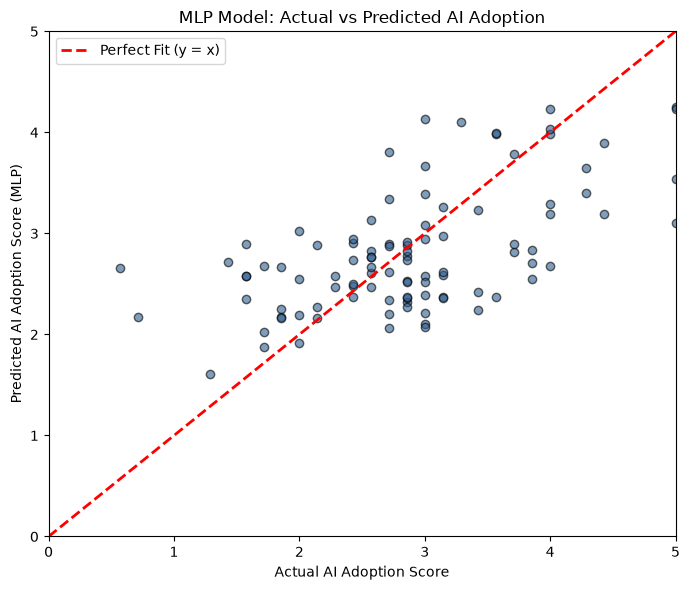

Plot saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\graphs\mlp_actual_vs_predicted.png


In [8]:
mlp.fit(X_scaled, y)
y_pred = mlp.predict(X_scaled)

plt.figure(figsize=(7, 6))
plt.scatter(y, y_pred, alpha=0.6, edgecolors="k", color="#2b5c8f")
plt.plot([0, 5], [0, 5], "r--", lw=2, label="Perfect Fit (y = x)")
plt.xlabel("Actual AI Adoption Score")
plt.ylabel("Predicted AI Adoption Score (MLP)")
plt.title("MLP Model: Actual vs Predicted AI Adoption")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.legend()
plt.tight_layout()

mlp_graph_path = GRAPHS_DIR / "mlp_actual_vs_predicted.png"
plt.savefig(mlp_graph_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print(f"Plot saved to: {mlp_graph_path}")